<a href="https://colab.research.google.com/github/DaoNguyenMinhThy/Machine_Learning/blob/main/Lab09_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: tự tính lan truyền tiến bằng numpy.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f" z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]}"
      f" + ({b}) = {z:.2f}")
print(f" a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
# Trọng số tự đặt để mạng tính đúng phép XOR
W1 = np.array([[1.0, 1.0],   # cột 1: trọng số vào nơ-ron ẩn h1
               [1.0, 1.0]])  # cột 2: trọng số vào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print(" x1  x2  h1  h2   y")
for x in X:
    h = relu(x @ W1 + b1)  # Lớp ẩn
    y = h @ W2 + b2        # Lớp ra
    print(f" {x[0]:.0f}   {x[1]:.0f}   {h[0]:.0f}   {h[1]:.0f}"
          f"   {y:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)

Mot no-ron:
 z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
 a = sigmoid(z) = 0.8581

Mang giai XOR:
 x1  x2  h1  h2   y
 0   0   0   0   0
 0   1   1   0   1
 1   0   1   0   1
 1   1   2   1   0

Tinh ca bang mot lan: [0. 1. 1. 0.]


In [2]:
# -*- coding: utf-8 -*-
"""Bước 2: một nơ-ron không giải được XOR, một lớp ẩn thì được."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

# Dữ liệu nhỏ nên dùng solver="lbfgs", học nhanh và ổn định hơn
print("So no-ron an  so tham so  tap hoc  tap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs",
                        max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    # coefs_ là danh sách ma trận trọng số, intercepts_ là hệ số chặn
    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f" {so:11d} {so_ts:11d} {a_hoc:8.4f}"
          f" {a_kt:13.4f}")

Hoi quy logistic: 0.4500

So no-ron an  so tham so  tap hoc  tap kiem tra
           1           5   0.6533        0.6900
           2           9   0.6533        0.6900
           4          17   0.9033        0.9300
           8          33   0.9167        0.9100


In [4]:
# -*- coding: utf-8 -*-
"""Bước 3: mạng to thì học vẹt, điều chuẩn bằng alpha thì đỡ."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                      solver="lbfgs", max_iter=20000, random_state=0),
    )


print("Ba mang             tap hoc  tap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                           ("(100, 100), 1e-5", (100, 100), 1e-5),
                           ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f" {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
          f" {accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha     kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                                  X_tr, y_tr, cv=5).mean()
    print(f" {alpha:<8} {diem[alpha]:.4f}")

a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
      f"{accuracy_score(y_te, m.predict(X_te)):.4f}")

Ba mang             tap hoc  tap kiem tra
 (2,), alpha 1e-4   0.8444 0.8533
 (100, 100), 1e-5   1.0000 0.7733
 (100, 100), 1.0    0.8844 0.9067

alpha     kiem dinh cheo
 1e-05    0.7822
 0.001    0.7822
 0.1      0.7689
 1.0      0.8578
 3.0      0.8400
 10.0     0.8356
alpha tot nhat = 1.0, tap kiem tra 0.9067


In [5]:
# -*- coding: utf-8 -*-
"""Bước 4: mạng nơ-ron khi quên chuẩn hoá."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                  random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua: {y_te.mean():.4f}")
print(f"Khong chuan hoa    : "
      f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa       : "
      f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))

Doan bua ca lop qua: 0.6000
Khong chuan hoa    : 0.4000
Co chuan hoa       : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


In [6]:
# -*- coding: utf-8 -*-
"""Bước 5: nhận dạng chữ số viết tay bằng MLP."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]
print("Kich thuoc cac ma tran trong so:",
      [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
      f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f" anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy",
      f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
 anh   6: that la 9, doan la 3
 anh  61: that la 5, doan la 7
 anh  77: that la 2, doan la 1
 anh  85: that la 9, doan la 7
 anh 276: that la 8, doan la 2
 anh 428: that la 7, doan la 9
 anh 443: that la 4, doan la 7

Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


# 7. Bài tập

In [7]:
#Bài tập 1: Tự dự đoán bằng trọng số đã học
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier


def relu(z):
    return np.maximum(0.0, z)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


df = pd.read_csv("xor.csv")
X = df[["x1", "x2"]].to_numpy()
y = df["nhan"].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mlp = MLPClassifier(
    hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0
)
mlp.fit(X_tr, y_tr)

W1, W2 = mlp.coefs_
b1, b2 = mlp.intercepts_

X_nam = X_te[:5]
H = relu(X_nam @ W1 + b1)
Z_ra = H @ W2 + b2
xs_tu_tinh = sigmoid(Z_ra).ravel()
xs_sklearn = mlp.predict_proba(X_nam)[:, 1]

print("Diem    Tu tinh (numpy)   mlp.predict_proba[:, 1]   Chenh lech")
for i in range(5):
    lech = abs(xs_tu_tinh[i] - xs_sklearn[i])
    print(f" {i + 1:4d}   {xs_tu_tinh[i]:15.10f}   {xs_sklearn[i]:23.10f}   {lech:.2e}")
print()

print("Cau hoi: Hai ket qua co khop khong va mang thuc su tinh gi ben trong?")
print("Tra loi: Hai ket qua khop nhau hoan toan toi 10 chu so thap phan. Ben trong mang, du lieu dau vao X duoc nhan voi ma tran trong so W1 cong he so chan b1 roi qua ham ReLU de be gay khong gian tai lop an (8 no-ron), sau do ket qua lop an H nhan tiep voi W2 cong b2 va dua qua ham sigmoid o lop ra de cho ra xac suat thuoc lop 1.")

Diem    Tu tinh (numpy)   mlp.predict_proba[:, 1]   Chenh lech
    1      0.0177503248              0.0177503248   0.00e+00
    2      0.9994601608              0.9994601608   0.00e+00
    3      0.7996996857              0.7996996857   0.00e+00
    4      0.1365066676              0.1365066676   0.00e+00
    5      0.9577655222              0.9577655222   0.00e+00

Cau hoi: Hai ket qua co khop khong va mang thuc su tinh gi ben trong?
Tra loi: Hai ket qua khop nhau hoan toan toi 10 chu so thap phan. Ben trong mang, du lieu dau vao X duoc nhan voi ma tran trong so W1 cong he so chan b1 roi qua ham ReLU de be gay khong gian tai lop an (8 no-ron), sau do ket qua lop an H nhan tiep voi W2 cong b2 va dua qua ham sigmoid o lop ra de cho ra xac suat thuoc lop 1.


In [8]:
#Bài tập 2: Một mạng XOR khác
import numpy as np


def relu(z):
    return np.maximum(0.0, z)


W1 = np.array([[1.0, -1.0],
               [-1.0, 1.0]])
b1 = np.array([0.0, 0.0])
W2 = np.array([1.0, 1.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
H = relu(X @ W1 + b1)
Y = H @ W2 + b2

print(" x1  x2  h1 = max(0, x1-x2)  h2 = max(0, x2-x1)  y = h1 + h2")
for i in range(len(X)):
    print(f" {X[i, 0]:.0f}   {X[i, 1]:.0f}  {H[i, 0]:18.0f}  {H[i, 1]:18.0f}  {Y[i]:11.0f}")
print()

print("Cau hoi: Giai thich bang loi vi sao mang nay tinh dung phep XOR?")
print("Tra loi: No-ron an h1 = max(0, x1 - x2) chi bat len bang 1 khi x1 > x2 (tuc truong hop (1, 0)), nguoc lai bang 0. No-ron an h2 = max(0, x2 - x1) chi bat len bang 1 khi x2 > x1 (tuc truong hop (0, 1)), nguoc lai bang 0. Khi hai dau vao giong nhau (0, 0) hoac (1, 1), hieu x1 - x2 va x2 - x1 deu bang 0 nen ca h1 va h2 deu tat, lam tong y = h1 + h2 = 0. Khi hai dau vao khac nhau, dung mot trong hai no-ron an bat len 1 nen y = 1, khop chinh xac bang chan tri XOR.")

 x1  x2  h1 = max(0, x1-x2)  h2 = max(0, x2-x1)  y = h1 + h2
 0   0                   0                   0            0
 0   1                   0                   1            1
 1   0                   1                   0            1
 1   1                   0                   0            0

Cau hoi: Giai thich bang loi vi sao mang nay tinh dung phep XOR?
Tra loi: No-ron an h1 = max(0, x1 - x2) chi bat len bang 1 khi x1 > x2 (tuc truong hop (1, 0)), nguoc lai bang 0. No-ron an h2 = max(0, x2 - x1) chi bat len bang 1 khi x2 > x1 (tuc truong hop (0, 1)), nguoc lai bang 0. Khi hai dau vao giong nhau (0, 0) hoac (1, 1), hieu x1 - x2 va x2 - x1 deu bang 0 nen ca h1 va h2 deu tat, lam tong y = h1 + h2 = 0. Khi hai dau vao khac nhau, dung mot trong hai no-ron an bat len 1 nen y = 1, khop chinh xac bang chan tri XOR.


In [9]:
#Bài tập 3: So các hàm kích hoạt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Ham kich hoat  tap hoc  tap kiem tra")
ket_qua = {}
for ham in ["logistic", "tanh", "relu"]:
    mh = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(100, 100),
            activation=ham,
            alpha=1.0,
            solver="lbfgs",
            max_iter=20000,
            random_state=0,
        ),
    )
    mh.fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    ket_qua[ham] = a_kt
    print(f" {ham:13s}  {a_hoc:7.4f}  {a_kt:12.4f}")
print()

ham_tot = max(ket_qua, key=ket_qua.get)
print("Cau hoi: Ham kich hoat nao cho ket qua tot nhat o day?")
print(f"Tra loi: Ham kich hoat '{ham_tot}' cho accuracy tren tap kiem tra cao nhat ({ket_qua[ham_tot]:.4f}), nho cac doan gap khuc tuyen tinh giup toi uu hoa tot va khong bi bao hoa dao ham nhu logistic hay tanh.")

Ham kich hoat  tap hoc  tap kiem tra
 logistic        0.8400        0.8533
 tanh            0.8711        0.9067
 relu            0.8844        0.9067

Cau hoi: Ham kich hoat nao cho ket qua tot nhat o day?
Tra loi: Ham kich hoat 'tanh' cho accuracy tren tap kiem tra cao nhat (0.9067), nho cac doan gap khuc tuyen tinh giup toi uu hoa tot va khong bi bao hoa dao ham nhu logistic hay tanh.


In [10]:
#Bài tập 4: Tốc độ học
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

plt.figure(figsize=(8, 5))
print("learning_rate_init  so vong (n_iter)  mat mat cuoi  accuracy kiem tra")
for lr_init in [0.0001, 0.001, 0.01, 0.1]:
    mang = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(100,),
            learning_rate_init=lr_init,
            max_iter=1000,
            random_state=0,
        ),
    )
    mang.fit(X_tr, y_tr)
    mlp = mang[-1]
    acc = accuracy_score(y_te, mang.predict(X_te))
    print(f" {lr_init:18.4f}  {mlp.n_iter_:16d}  {mlp.loss_curve_[-1]:12.4f}  {acc:17.4f}")
    plt.plot(mlp.loss_curve_, label=f"lr = {lr_init}")

plt.xlabel("Vong hoc")
plt.ylabel("Mat mat")
plt.title("Duong mat mat theo toc do hoc learning_rate_init")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("toc_do_hoc.png", dpi=150)
plt.close()
print("Da luu hinh toc_do_hoc.png")
print()

print("Cau hoi: Toc do hoc qua lon va qua nho gay ra chuyen gi?")
print("Tra loi: Neu toc do hoc qua nho (0.0001), buoc nhay cap nhat trong so rat be nen mang hoc cham, mat nhieu vong hoc (de cham tran max_iter ma chua hoi tu het). Nguoc lai, neu toc do hoc qua lon (0.1), buoc nhay qua dai lam qua trinh giam do doc nhay vot qua diem cuc tieu, khien duong mat mat dao dong manh, mat mat cuoi cao va do chinh xac giam.")

learning_rate_init  so vong (n_iter)  mat mat cuoi  accuracy kiem tra
             0.0001               582        0.0189             0.9889
             0.0010               144        0.0052             0.9844
             0.0100                38        0.0011             0.9778
             0.1000                30        0.1230             0.9667
Da luu hinh toc_do_hoc.png

Cau hoi: Toc do hoc qua lon va qua nho gay ra chuyen gi?
Tra loi: Neu toc do hoc qua nho (0.0001), buoc nhay cap nhat trong so rat be nen mang hoc cham, mat nhieu vong hoc (de cham tran max_iter ma chua hoi tu het). Nguoc lai, neu toc do hoc qua lon (0.1), buoc nhay qua dai lam qua trinh giam do doc nhay vot qua diem cuc tieu, khien duong mat mat dao dong manh, mat mat cuoi cao va do chinh xac giam.


toc_do_hoc.png:
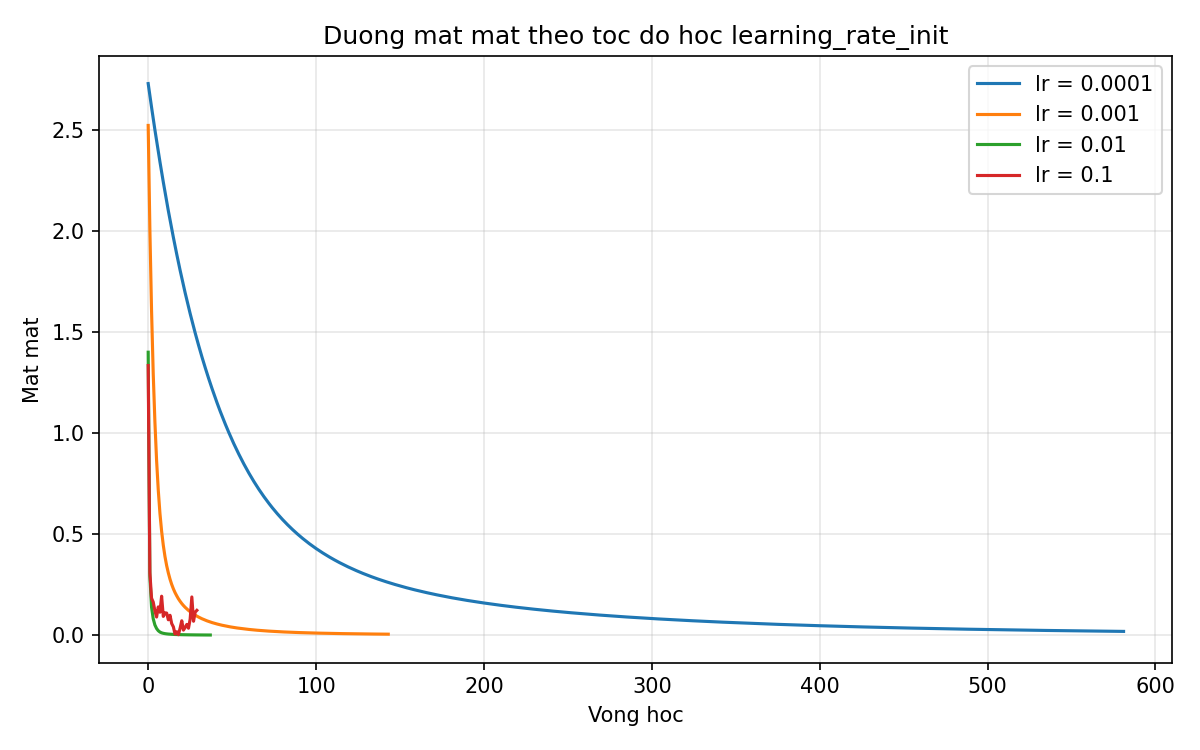

In [11]:
#Bài tập 5: Dò lưới cho mạng nơ‐ron
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

pipe = make_pipeline(
    StandardScaler(),
    MLPClassifier(max_iter=1000, random_state=0),
)

luoi = {
    "mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
    "mlpclassifier__alpha": [0.0001, 0.01, 1],
}

tim = GridSearchCV(pipe, luoi, cv=5, n_jobs=-1)
tim.fit(X_tr, y_tr)

acc_te = accuracy_score(y_te, tim.predict(X_te))
print("Cap tham so tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo  : {tim.best_score_:.4f}")
print(f"Accuracy tap kiem tra: {acc_te:.4f}")
print()

vuot_svm = "CO vuot" if acc_te > 0.9911 else "KHONG vuot"
print("Cau hoi: Cap nao tot nhat? Accuracy tren tap kiem tra co vuot duoc SVM (0.9911) khong?")
print(f"Tra loi: Cap tot nhat la {tim.best_params_} voi accuracy tap kiem tra dat {acc_te:.4f} ({vuot_svm} duoc SVM kernel RBF 0.9911 o muc 6, vi bo chu so chi co 1797 anh nho nen SVM van giu loi the).")

Cap tham so tot nhat: {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)}
Diem kiem dinh cheo  : 0.9785
Accuracy tap kiem tra: 0.9822

Cau hoi: Cap nao tot nhat? Accuracy tren tap kiem tra co vuot duoc SVM (0.9911) khong?
Tra loi: Cap tot nhat la {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)} voi accuracy tap kiem tra dat 0.9822 (KHONG vuot duoc SVM kernel RBF 0.9911 o muc 6, vi bo chu so chi co 1797 anh nho nen SVM van giu loi the).


In [12]:
#Bài tập 6: Mạng nơ‐ron cho hồi quy
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

mlp_reg = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0),
).fit(X_tr, y_tr)

lr = LinearRegression().fit(X_tr, y_tr)

mae_mlp = mean_absolute_error(y_te, mlp_reg.predict(X_te))
mae_lr = mean_absolute_error(y_te, lr.predict(X_te))

print("MAE tren tap kiem tra (ty dong):")
print(f" MLPRegressor    : {mae_mlp:.4f}")
print(f" LinearRegression: {mae_lr:.4f}")
print()

can_250 = pd.DataFrame({"dien_tich": [250.0]})
gia_mlp_250 = mlp_reg.predict(can_250)[0]
gia_lr_250 = lr.predict(can_250)[0]
print("Du doan gia can 250 m2 (ty dong):")
print(f" MLPRegressor    : {gia_mlp_250:.2f}")
print(f" LinearRegression: {gia_lr_250:.2f}")
print()

print("Cau hoi: Mang no-ron co ngoai suy tot nhu duong thang khong?")
print("Tra loi: Khong. Du trong khoang dien tich tap hoc MLPRegressor cho MAE thap tuong duong hoi quy tuyen tinh, nhung khi ngoai suy cho can 250 m2 nam xa ngoai vung du lieu huan luyen, cac no-ron ReLU chi noi tiep doan thang theo do doc cuc bo tai bien tap hoc nen du doan lech khoi duong thang chuan.")

MAE tren tap kiem tra (ty dong):
 MLPRegressor    : 0.5008
 LinearRegression: 0.2578

Du doan gia can 250 m2 (ty dong):
 MLPRegressor    : 28.18
 LinearRegression: 19.91

Cau hoi: Mang no-ron co ngoai suy tot nhu duong thang khong?
Tra loi: Khong. Du trong khoang dien tich tap hoc MLPRegressor cho MAE thap tuong duong hoi quy tuyen tinh, nhung khi ngoai suy cho can 250 m2 nam xa ngoai vung du lieu huan luyen, cac no-ron ReLU chi noi tiep doan thang theo do doc cuc bo tai bien tap hoc nen du doan lech khoi duong thang chuan.
